In [ ]:

# ==========================================
# BLOK 1: Import biblioteka i učitavanje podataka
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
from scipy.spatial.distance import cdist
import warnings
warnings.filterwarnings('ignore')

# Učitavanje dataseta
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/clean_dataset.csv')

print("Dimenzije dataseta:", df.shape)
print("\nPrvih 5 redova:")
print(df.head())
print("\nInfo o podacima:")
print(df.info())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dimenzije dataseta: (10127, 20)

Prvih 5 redova:
  Attrition_Flag_clean  Customer_Age_clean Gender_clean  \
0    Existing Customer                45.0            M   
1    Existing Customer                49.0            F   
2    Existing Customer                46.0            M   
3    Existing Customer                46.0            F   
4    Existing Customer                46.0            M   

   Dependent_count_clean Education_Level_clean Marital_Status_clean  \
0                    3.0           High School              Married   
1                    5.0              Graduate               Single   
2                    3.0              Graduate              Married   
3                    4.0           High School              Unknown   
4                    3.0            Uneducated              Married   

  Income_Category_clean Card_Category_cl

In [ ]:
# ==========================================
# BLOK 2: Priprema podataka
# ==========================================

# Uklanjanje ciljne varijable
if 'Attrition_Flag_clean' in df.columns:
    df = df.drop('Attrition_Flag_clean', axis=1)
    print("\nCiljna varijabla 'Attrition_Flag_clean' je uklonjena.")

# Razdvajanje numeričkih i kategorijalnih varijabli
num_features = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
cat_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"\nNumeričke varijable ({len(num_features)}):", num_features)
print(f"Kategorijalne varijable ({len(cat_features)}):", cat_features)

# Rješavanje nedostajućih podataka
df[num_features] = df[num_features].fillna(df[num_features].mean())
df[cat_features] = df[cat_features].fillna("Unknown")

# Kreiranje preprocessora
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ]
)

# Transformacija podataka
X_processed = preprocessor.fit_transform(df)
print(f"\nDimenzije transformisanih podataka: {X_processed.shape}")


Ciljna varijabla 'Attrition_Flag_clean' je uklonjena.

Numeričke varijable (14): ['Customer_Age_clean', 'Dependent_count_clean', 'Months_on_book_clean', 'Total_Relationship_Count_clean', 'Months_Inactive_clean', 'Contacts_Count_clean', 'Credit_Limit_clean', 'Total_Revolving_Bal_clean', 'Avg_Open_To_Buy_clean', 'Total_Amt_Chng_clean', 'Total_Trans_Amt_clean', 'Total_Trans_Ct_clean', 'Total_Ct_Chng_clean', 'Avg_Utilization_Ratio_clean']
Kategorijalne varijable (5): ['Gender_clean', 'Education_Level_clean', 'Marital_Status_clean', 'Income_Category_clean', 'Card_Category_clean']

Dimenzije transformisanih podataka: (10127, 38)



Broj PCA komponenti (90% varijanse): 17
Objašnjena varijansa: 0.9083


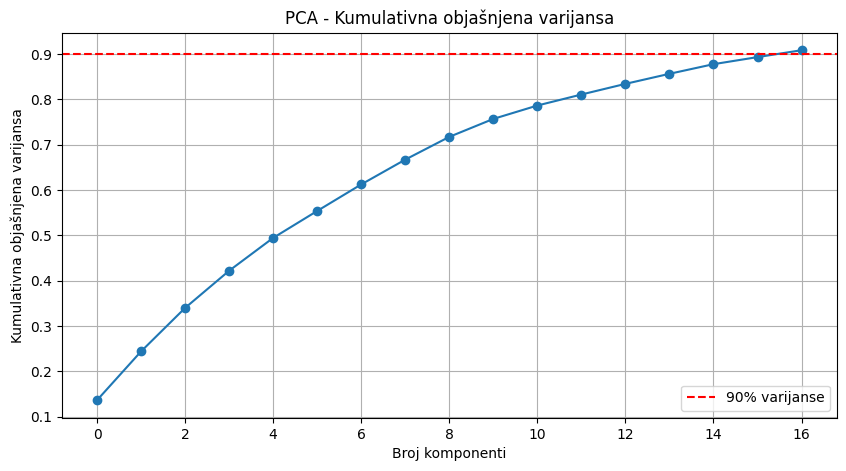

In [ ]:
# ==========================================
# BLOK 3: PCA redukcija dimenzionalnosti
# ==========================================

# PCA sa 90% varijanse
pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_processed)

print(f"\nBroj PCA komponenti (90% varijanse): {X_pca.shape[1]}")
print(f"Objašnjena varijansa: {pca.explained_variance_ratio_.sum():.4f}")

# Vizualizacija kumulativne varijanse
plt.figure(figsize=(10, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel('Broj komponenti')
plt.ylabel('Kumulativna objašnjena varijansa')
plt.title('PCA - Kumulativna objašnjena varijansa')
plt.grid(True)
plt.axhline(y=0.90, color='r', linestyle='--', label='90% varijanse')
plt.legend()
plt.show()

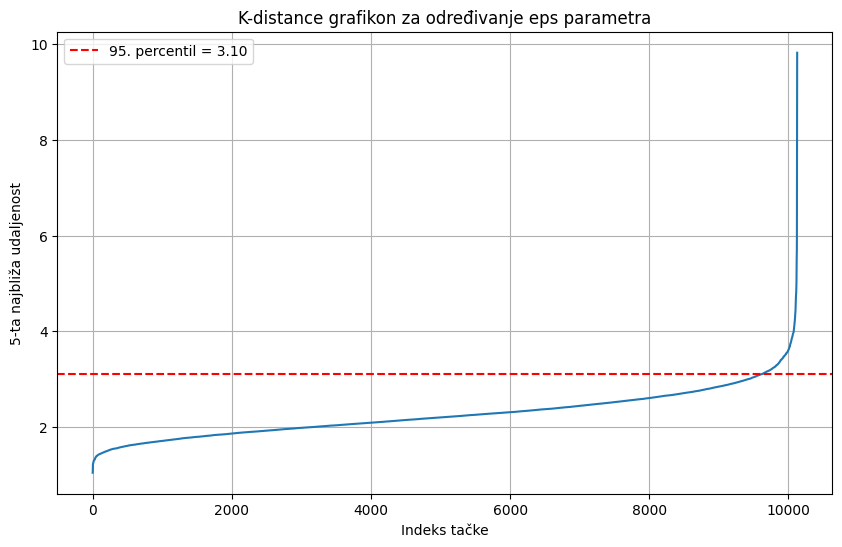


Preporučene eps vrijednosti:
90. percentil: 2.8761
95. percentil: 3.1048
98. percentil: 3.4489


In [ ]:
# ==========================================
# BLOK 4: Određivanje optimalnih DBSCAN parametara
# ==========================================

# K-distance grafikon za određivanje eps parametra
k = 5  # MinPts = broj dimenzija + 1
neighbors = NearestNeighbors(n_neighbors=k)
neighbors_fit = neighbors.fit(X_pca)
distances, indices = neighbors_fit.kneighbors(X_pca)

# Sortiranje udaljenosti
distances = np.sort(distances[:, k-1], axis=0)

# Vizualizacija k-distance grafikona
plt.figure(figsize=(10, 6))
plt.plot(distances)
plt.xlabel('Indeks tačke')
plt.ylabel(f'{k}-ta najbliža udaljenost')
plt.title('K-distance grafikon za određivanje eps parametra')
plt.grid(True)
plt.axhline(y=np.percentile(distances, 95), color='r', linestyle='--',
            label=f'95. percentil = {np.percentile(distances, 95):.2f}')
plt.legend()
plt.show()

print(f"\nPreporučene eps vrijednosti:")
print(f"90. percentil: {np.percentile(distances, 90):.4f}")
print(f"95. percentil: {np.percentile(distances, 95):.4f}")
print(f"98. percentil: {np.percentile(distances, 98):.4f}")


In [ ]:
# ==========================================
# BLOK 5: Testiranje različitih DBSCAN parametara
# ==========================================

# Testiranje različitih kombinacija eps i min_samples
eps_values = [1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3,3.2,3.5]
min_samples_values = [20, 25, 30, 35, 40,70,100]

results = []

print("\nTestiranje DBSCAN parametara...")
print("-" * 80)

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1)
        labels = dbscan.fit_predict(X_pca)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        if n_clusters > 1:  # Potrebno je bar 2 klastera za metrike
            try:
                # Filtriranje šuma za metrike
                mask = labels != -1
                X_filtered = X_pca[mask]
                labels_filtered = labels[mask]

                silhouette = silhouette_score(X_filtered, labels_filtered)
                davies_bouldin = davies_bouldin_score(X_filtered, labels_filtered)
                calinski = calinski_harabasz_score(X_filtered, labels_filtered)

                results.append({
                    'eps': eps,
                    'min_samples': min_samples,
                    'n_clusters': n_clusters,
                    'n_noise': n_noise,
                    'noise_ratio': n_noise / len(labels),
                    'silhouette': silhouette,
                    'davies_bouldin': davies_bouldin,
                    'calinski': calinski
                })

                print(f"eps={eps:.1f}, min_samples={min_samples:2d} | "
                      f"Klasteri={n_clusters:2d}, Šum={n_noise:5d} ({n_noise/len(labels)*100:.1f}%) | "
                      f"Silh={silhouette:.3f}, DB={davies_bouldin:.3f}, CH={calinski:.1f}")
            except:
                pass

results_df = pd.DataFrame(results)


Testiranje DBSCAN parametara...
--------------------------------------------------------------------------------
eps=1.8, min_samples=20 | Klasteri= 3, Šum= 9102 (89.9%) | Silh=-0.003, DB=1.672, CH=15.5
eps=1.8, min_samples=30 | Klasteri= 2, Šum= 9561 (94.4%) | Silh=0.103, DB=1.906, CH=38.9
eps=1.8, min_samples=35 | Klasteri= 4, Šum= 9765 (96.4%) | Silh=0.139, DB=1.957, CH=54.9
eps=1.8, min_samples=40 | Klasteri= 3, Šum= 9875 (97.5%) | Silh=0.152, DB=2.043, CH=43.6
eps=2.0, min_samples=20 | Klasteri= 2, Šum= 7017 (69.3%) | Silh=0.147, DB=1.285, CH=24.4
eps=2.0, min_samples=70 | Klasteri= 2, Šum= 9329 (92.1%) | Silh=0.128, DB=1.787, CH=62.3
eps=2.2, min_samples=20 | Klasteri= 2, Šum= 4916 (48.5%) | Silh=0.321, DB=0.942, CH=110.8
eps=2.2, min_samples=25 | Klasteri= 2, Šum= 5187 (51.2%) | Silh=0.325, DB=0.928, CH=92.3
eps=2.2, min_samples=30 | Klasteri= 2, Šum= 5444 (53.8%) | Silh=0.332, DB=0.918, CH=97.7
eps=2.4, min_samples=20 | Klasteri= 2, Šum= 3177 (31.4%) | Silh=0.234, DB=1.140, CH

In [ ]:
# ==========================================
# BLOK 6: Odabir optimalne konfiguracije
# ==========================================

# Filtriranje rezultata sa razumnim brojem klastera i šuma
filtered_results = results_df[
    (results_df['n_clusters'] >= 2) &
    (results_df['n_clusters'] <= 8) &
    (results_df['noise_ratio'] < 0.65)  # Dozvoljavamo do 65% šuma
]
# filtered_results = results_df[
#     (results_df['n_clusters'] >= 2) &
#     (results_df['n_clusters'] <= 8) &
#     (results_df['noise_ratio'] < 0.50) &  # Srednji šum
#     (results_df['silhouette'] > 0.20)     # Minimalni kvalitet
# ]

if len(filtered_results) > 0:
    # Odabir na osnovu Silhouette score-a
    best_config = filtered_results.loc[filtered_results['silhouette'].idxmax()]

    print("\n" + "="*80)
    print("OPTIMALNA KONFIGURACIJA:")
    print("="*80)
    print(f"eps: {best_config['eps']}")
    print(f"min_samples: {int(best_config['min_samples'])}")
    print(f"Broj klastera: {int(best_config['n_clusters'])}")
    print(f"Broj šum tačaka: {int(best_config['n_noise'])} ({best_config['noise_ratio']*100:.2f}%)")
    print(f"Silhouette Score: {best_config['silhouette']:.4f}")
    print(f"Davies-Bouldin Score: {best_config['davies_bouldin']:.4f}")
    print(f"Calinski-Harabasz Score: {best_config['calinski']:.2f}")

    optimal_eps = best_config['eps']
    optimal_min_samples = int(best_config['min_samples'])
else:
    print("\nUpozorenje: Koriste se default parametri")
    optimal_eps = 2.0
    optimal_min_samples = 10


OPTIMALNA KONFIGURACIJA:
eps: 2.2
min_samples: 30
Broj klastera: 2
Broj šum tačaka: 5444 (53.76%)
Silhouette Score: 0.3320
Davies-Bouldin Score: 0.9176
Calinski-Harabasz Score: 97.74


In [ ]:
# ==========================================
# BLOK 7: Finalni DBSCAN model
# ==========================================

# Izgradnja finalnog modela
final_dbscan = DBSCAN(eps=optimal_eps, min_samples=optimal_min_samples, n_jobs=-1)
final_labels = final_dbscan.fit_predict(X_pca)

# Analiza rezultata
n_clusters_final = len(set(final_labels)) - (1 if -1 in final_labels else 0)
n_noise_final = list(final_labels).count(-1)

print(f"\n\nFINALNI MODEL - REZULTATI:")
print("="*80)
print(f"Broj identifikovanih klastera: {n_clusters_final}")
print(f"Broj šum tačaka: {n_noise_final} ({n_noise_final/len(final_labels)*100:.2f}%)")

# Distribucija tačaka po klasterima
unique, counts = np.unique(final_labels, return_counts=True)
print("\nDistribucija tačaka po klasterima:")
for label, count in zip(unique, counts):
    if label == -1:
        print(f"  Šum: {count} tačaka ({count/len(final_labels)*100:.2f}%)")
    else:
        print(f"  Klaster {label}: {count} tačaka ({count/len(final_labels)*100:.2f}%)")

# Evaluacija (bez šuma)
if n_clusters_final > 1:
    mask = final_labels != -1
    X_filtered = X_pca[mask]
    labels_filtered = final_labels[mask]

    silhouette_final = silhouette_score(X_filtered, labels_filtered)
    davies_bouldin_final = davies_bouldin_score(X_filtered, labels_filtered)
    calinski_final = calinski_harabasz_score(X_filtered, labels_filtered)

    print(f"\nMetrike validacije (bez šuma):")
    print(f"  Silhouette Score: {silhouette_final:.4f}")
    print(f"  Davies-Bouldin Score: {davies_bouldin_final:.4f}")
    print(f"  Calinski-Harabasz Score: {calinski_final:.2f}")



FINALNI MODEL - REZULTATI:
Broj identifikovanih klastera: 2
Broj šum tačaka: 5444 (53.76%)

Distribucija tačaka po klasterima:
  Šum: 5444 tačaka (53.76%)
  Klaster 0: 4651 tačaka (45.93%)
  Klaster 1: 32 tačaka (0.32%)

Metrike validacije (bez šuma):
  Silhouette Score: 0.3320
  Davies-Bouldin Score: 0.9176
  Calinski-Harabasz Score: 97.74


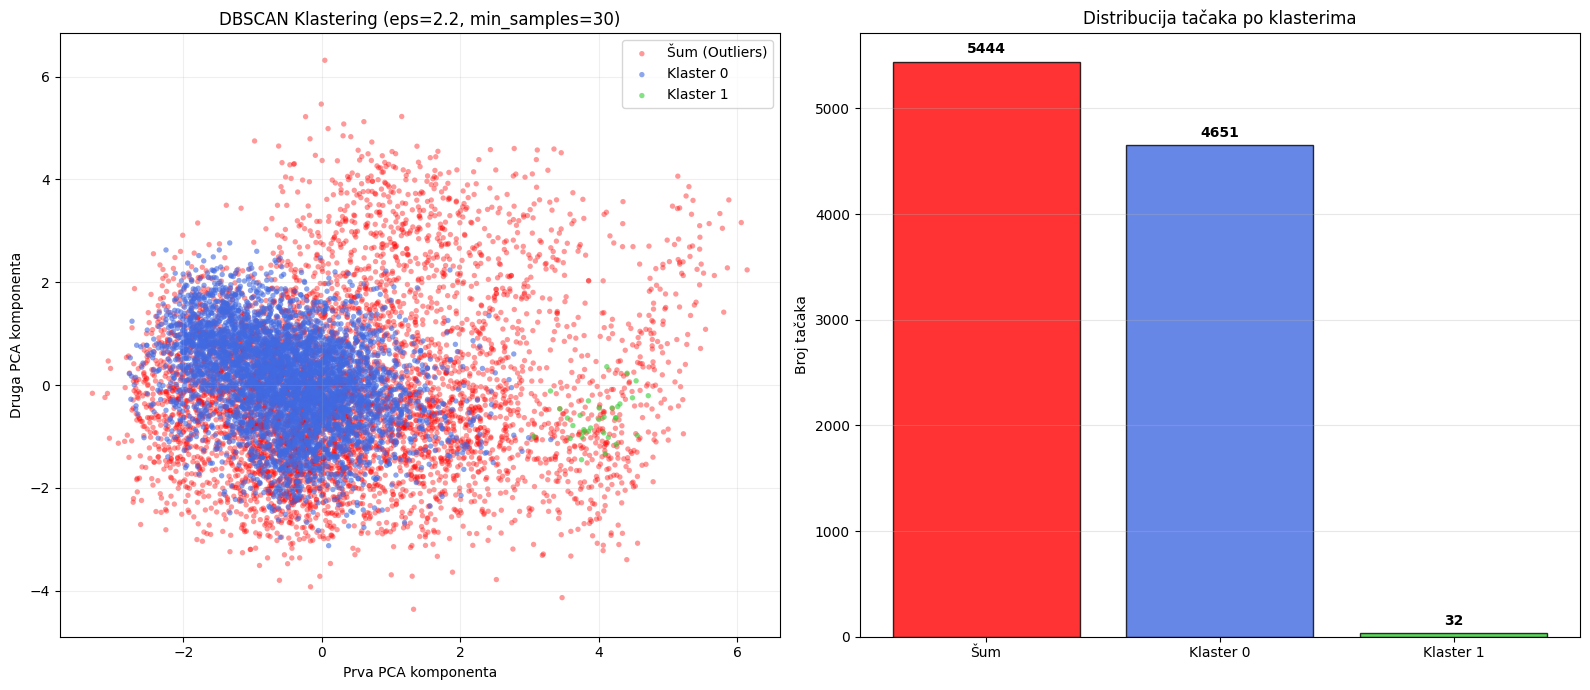

In [ ]:
# ==========================================
# BLOK 8: Vizualizacija rezultata (POBOLJŠANE BOJE)
# ==========================================

import matplotlib.patches as mpatches

plt.figure(figsize=(16, 7))

# --- 1. GRAFIKON: 2D SCATTER PLOT ---
plt.subplot(1, 2, 1)
unique_labels = np.unique(final_labels)
colors_map = {-1: 'red', 0: 'royalblue', 1: 'limegreen', 2: 'orange', 3: 'purple'}

# Iscrtavamo svaku grupu posebno radi kontrole boja i legende
for label in unique_labels:
    mask = (final_labels == label)
    color = colors_map.get(label, 'gray')
    label_name = 'Šum (Outliers)' if label == -1 else f'Klaster {label}'
    alpha = 0.4 if label == -1 else 0.6

    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=color, label=label_name, s=15, alpha=alpha, edgecolors='none')

plt.xlabel('Prva PCA komponenta')
plt.ylabel('Druga PCA komponenta')
plt.title(f'DBSCAN Klastering (eps={optimal_eps}, min_samples={optimal_min_samples})')
plt.legend(loc='best')
plt.grid(True, alpha=0.2)

# --- 2. GRAFIKON: DISTRIBUCIJA (BAR CHART) ---
plt.subplot(1, 2, 2)

cluster_sizes = [np.sum(final_labels == label) for label in unique_labels]
bar_colors = [colors_map.get(label, 'gray') for label in unique_labels]
labels_str = ['Šum' if label == -1 else f'Klaster {label}' for label in unique_labels]

bars = plt.bar(range(len(unique_labels)), cluster_sizes, color=bar_colors, edgecolor='black', alpha=0.8)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, int(yval), ha='center', va='bottom', fontweight='bold')

plt.xticks(range(len(unique_labels)), labels_str, rotation=0)
plt.ylabel('Broj tačaka')
plt.title('Distribucija tačaka po klasterima')
plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


PROFILISANJE KLASTERA

Prosječne vrijednosti numeričkih varijabli po klasterima:
         Customer_Age_clean  Credit_Limit_clean  Total_Trans_Amt_clean  \
Cluster                                                                  
0                     46.17             4761.43                3871.91   
1                     45.88            33240.28                3910.31   

         Total_Trans_Ct_clean  Months_on_book_clean  \
Cluster                                               
0                       67.84                 35.88   
1                       68.69                 35.34   

         Total_Relationship_Count_clean  
Cluster                                  
0                                  4.00  
1                                  4.03  

Dominantan nivo obrazovanja po klasterima:
  Klaster 0: Graduate
  Klaster 1: College


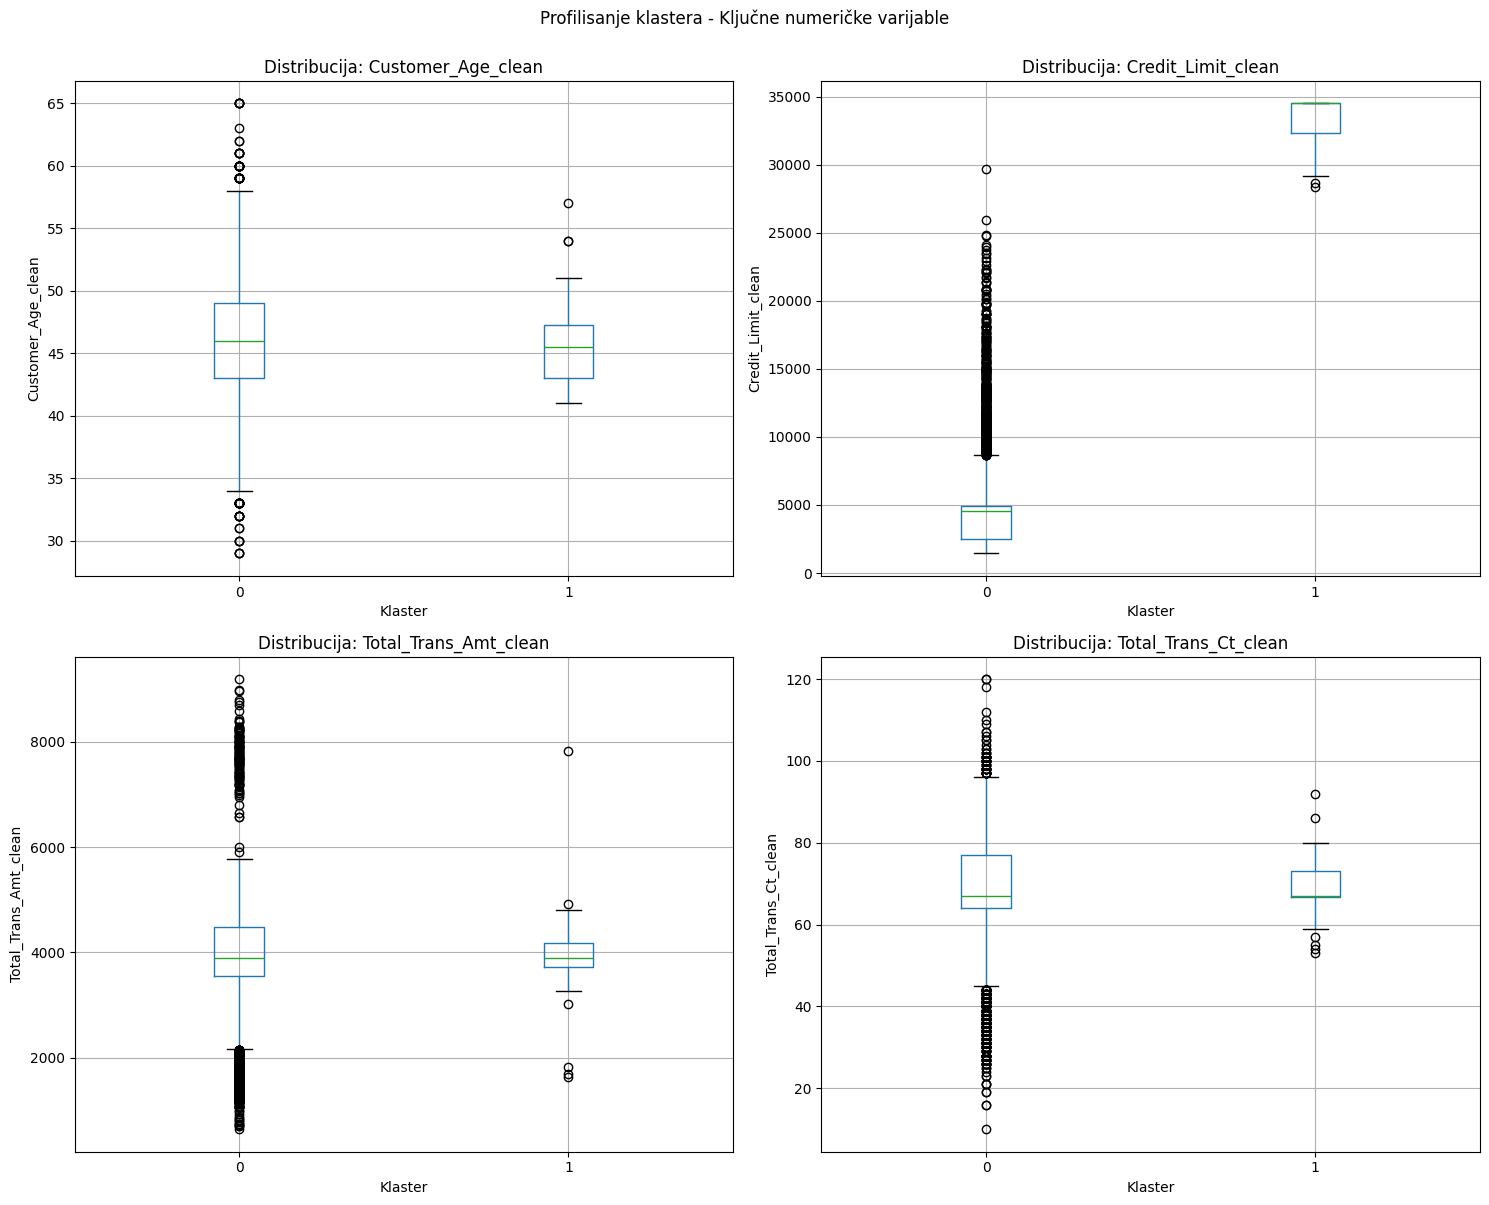

In [ ]:
# ==========================================
# BLOK 9: Analiza klastera (profilisanje)
# ==========================================

# Dodavanje labela originalnom dataframu
df_analyzed = df.copy()
df_analyzed['Cluster'] = final_labels

# Analiza samo klastera (bez šuma)
clusters_only = df_analyzed[df_analyzed['Cluster'] != -1]

if len(clusters_only) > 0:
    print("\n" + "="*80)
    print("PROFILISANJE KLASTERA")
    print("="*80)

    # Odabir ključnih numeričkih varijabli za analizu
    key_numeric_features = ['Customer_Age_clean', 'Credit_Limit_clean',
                           'Total_Trans_Amt_clean', 'Total_Trans_Ct_clean',
                           'Months_on_book_clean', 'Total_Relationship_Count_clean']

    # Provjera koje varijable postoje
    available_features = [f for f in key_numeric_features if f in clusters_only.columns]

    # Grupna statistika
    cluster_profile = clusters_only.groupby('Cluster')[available_features].mean()
    print("\nProsječne vrijednosti numeričkih varijabli po klasterima:")
    print(cluster_profile.round(2))

    # Analiza kategorijalnih varijabli
    if 'Education_Level_clean' in clusters_only.columns:
        print("\nDominantan nivo obrazovanja po klasterima:")
        for cluster in sorted(clusters_only['Cluster'].unique()):
            mode_education = clusters_only[clusters_only['Cluster'] == cluster]['Education_Level_clean'].mode()
            if len(mode_education) > 0:
                print(f"  Klaster {cluster}: {mode_education.values[0]}")

    # Vizualizacija profila klastera
    if len(available_features) >= 3:
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        axes = axes.ravel()

        for idx, feature in enumerate(available_features[:4]):
            clusters_only.boxplot(column=feature, by='Cluster', ax=axes[idx])
            axes[idx].set_title(f'Distribucija: {feature}')
            axes[idx].set_xlabel('Klaster')
            axes[idx].set_ylabel(feature)
            plt.sca(axes[idx])
            plt.xticks(rotation=0)

        plt.suptitle('Profilisanje klastera - Ključne numeričke varijable', y=1.00)
        plt.tight_layout()
        plt.show()



POREĐENJE DBSCAN SA K-MEANS (k=4)

K-means (k=4):
  Silhouette Score: 0.0984
  Davies-Bouldin Score: 2.4344
  Calinski-Harabasz Score: 935.09

DBSCAN (Tvoj model):
  Silhouette Score: 0.3320
  Davies-Bouldin Score: 0.9176
  Calinski-Harabasz Score: 97.74


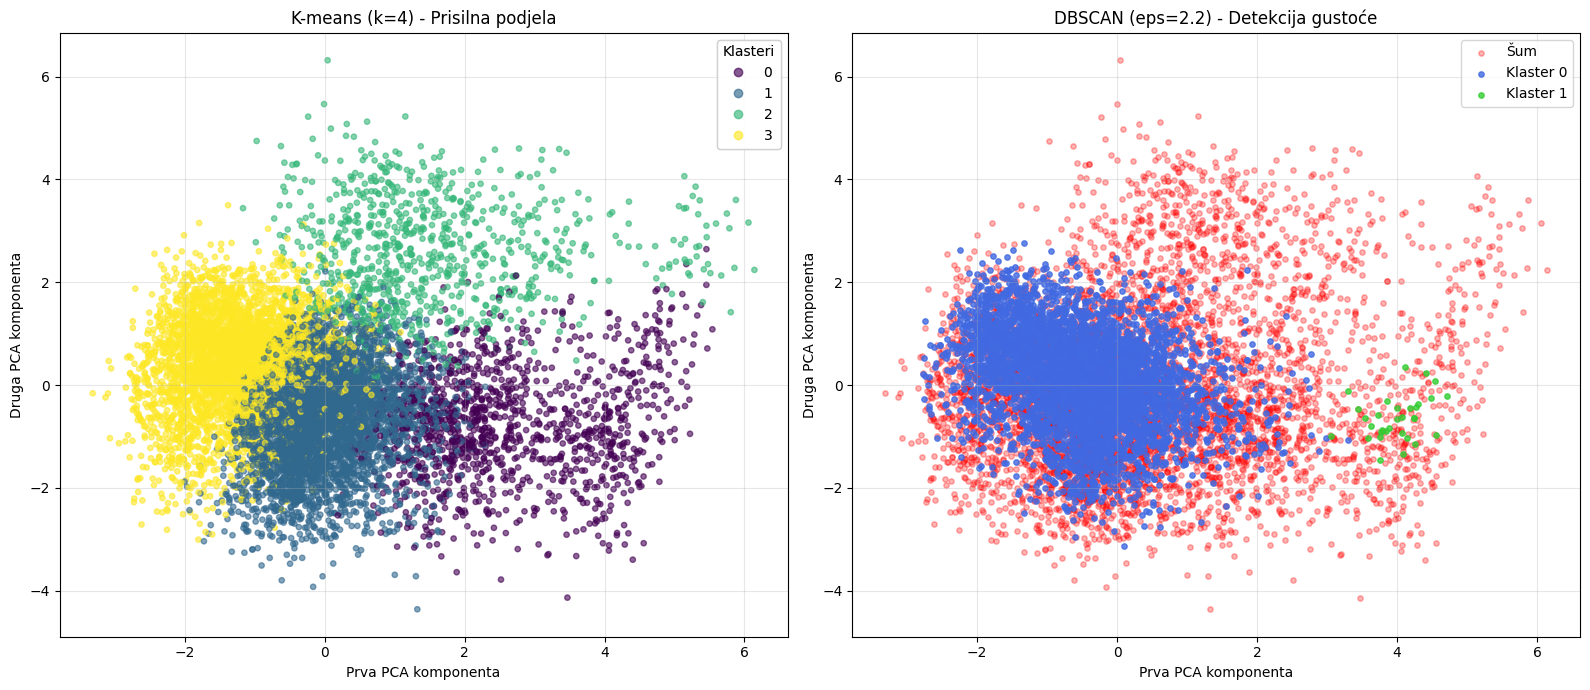


ANALIZA ZAVRŠENA


In [ ]:
# ==========================================
# BLOK 10: Poređenje sa drugim metodama (K-Means k=4)
# ==========================================

print("\n" + "="*80)
print("POREĐENJE DBSCAN SA K-MEANS (k=4)")
print("="*80)

from sklearn.cluster import KMeans

# 1. K-MEANS SA 4 KLASTERA (Fiksirano prema Zadatku 1)
k_means_clusters = 4
kmeans = KMeans(n_clusters=k_means_clusters, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)

# Izračunavanje metrika za K-Means
silhouette_kmeans = silhouette_score(X_pca, kmeans_labels)
davies_bouldin_kmeans = davies_bouldin_score(X_pca, kmeans_labels)
calinski_kmeans = calinski_harabasz_score(X_pca, kmeans_labels)

print(f"\nK-means (k={k_means_clusters}):")
print(f"  Silhouette Score: {silhouette_kmeans:.4f}")
print(f"  Davies-Bouldin Score: {davies_bouldin_kmeans:.4f}")
print(f"  Calinski-Harabasz Score: {calinski_kmeans:.2f}")

print(f"\nDBSCAN (Tvoj model):")
print(f"  Silhouette Score: {silhouette_final:.4f}")
print(f"  Davies-Bouldin Score: {davies_bouldin_final:.4f}")
print(f"  Calinski-Harabasz Score: {calinski_final:.2f}")

# 2. VIZUALIZACIJA POREĐENJA
import matplotlib.patches as mpatches

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Lijevo: K-Means (k=4) ---
scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels,
                    cmap='viridis', s=15, alpha=0.6)
axes[0].set_xlabel('Prva PCA komponenta')
axes[0].set_ylabel('Druga PCA komponenta')
axes[0].set_title(f'K-means (k={k_means_clusters}) - Prisilna podjela')
axes[0].grid(True, alpha=0.3)
# Dodajemo legendu za K-means
legend1 = axes[0].legend(*scatter1.legend_elements(), title="Klasteri")
axes[0].add_artist(legend1)

# --- Desno: DBSCAN (Tvoj rezultat) ---
# Koristimo istu logiku boja kao u Bloku 8 (Crveno za šum)
unique_labels_db = np.unique(final_labels)
colors_map = {-1: 'red', 0: 'royalblue', 1: 'limegreen', 2: 'orange', 3: 'purple'}

for label in unique_labels_db:
    mask = (final_labels == label)
    color = colors_map.get(label, 'gray')
    label_name = 'Šum' if label == -1 else f'Klaster {label}'
    alpha = 0.3 if label == -1 else 0.8

    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=color, label=label_name, s=15, alpha=alpha)

axes[1].set_xlabel('Prva PCA komponenta')
axes[1].set_ylabel('Druga PCA komponenta')
axes[1].set_title(f'DBSCAN (eps={optimal_eps}) - Detekcija gustoće')
axes[1].legend(loc='best')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("ANALIZA ZAVRŠENA")
print("="*80)

Generisanje grafika za testiranje hipoteza...


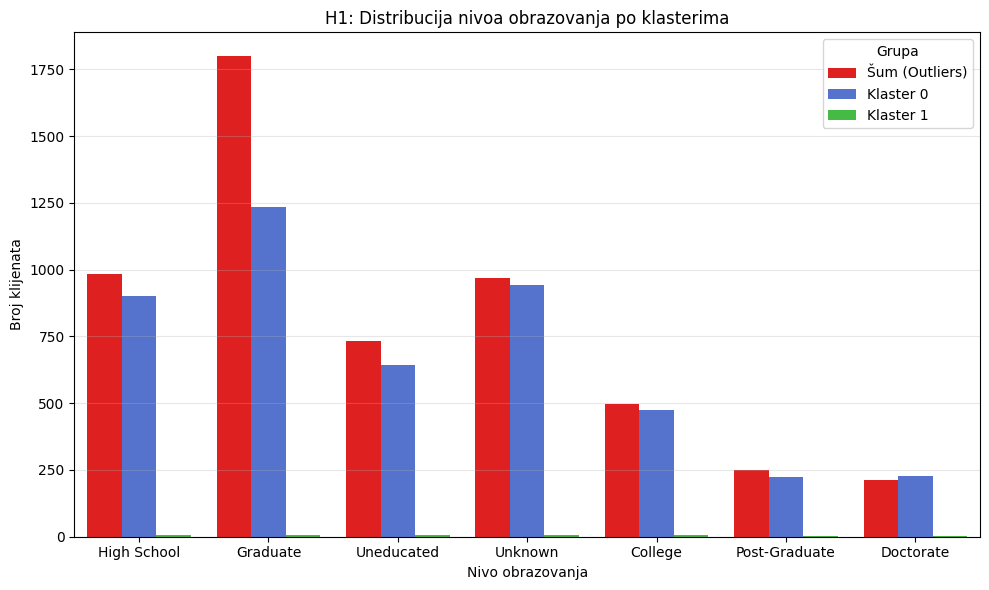

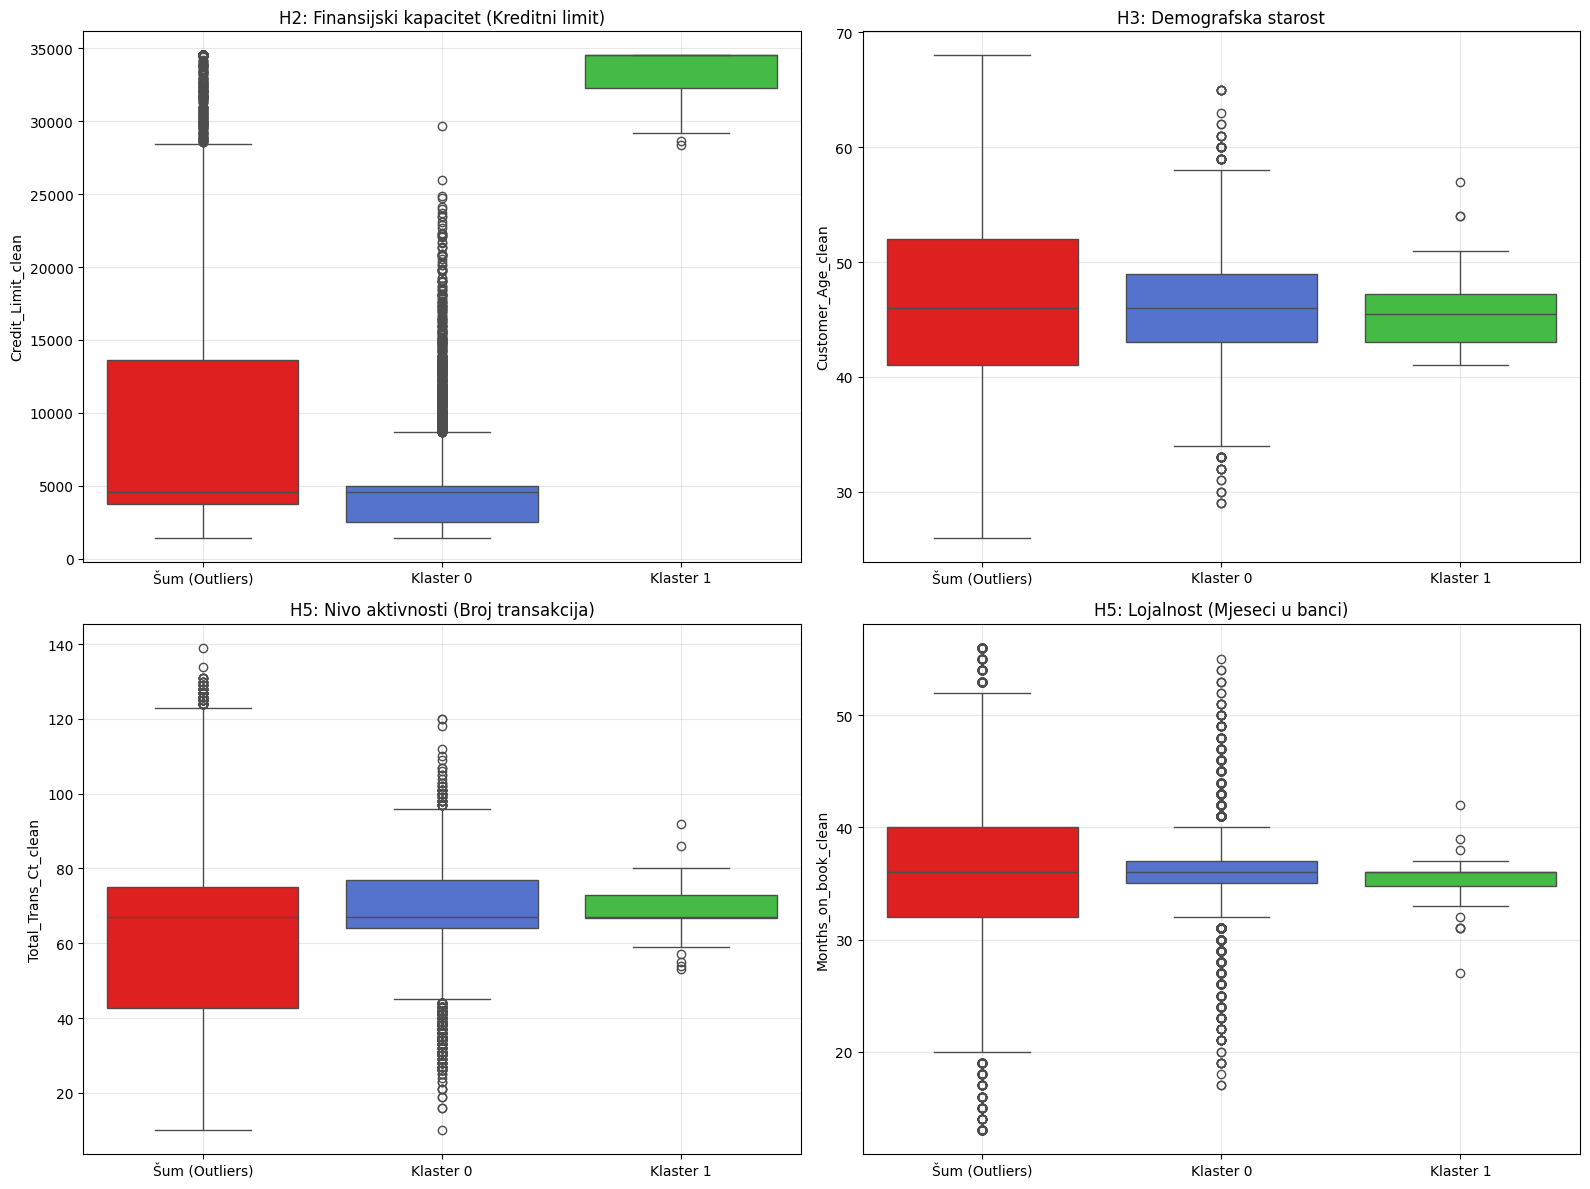

In [ ]:
# ==========================================
# BLOK 11: Vizualizacija za testiranje hipoteza (H1 - H5)
# ==========================================
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Priprema dataframe-a za vizualizaciju
df_hyp = df.copy()
df_hyp['Cluster_ID'] = final_labels

# -1 postaje "Šum", ostali su "Klaster X"
df_hyp['Cluster_Label'] = df_hyp['Cluster_ID'].apply(
    lambda x: 'Šum (Outliers)' if x == -1 else f'Klaster {x}'
)

order_list = ['Šum (Outliers)', 'Klaster 0', 'Klaster 1']
# Boje: Šum=Crvena, Klaster 0=Plava, Klaster 1=Zelena
custom_palette = {'Šum (Outliers)': 'red', 'Klaster 0': 'royalblue', 'Klaster 1': 'limegreen'}

# Filtriramo samo varijable potrebne za hipoteze
vars_to_plot = [
    'Education_Level_clean',      # H1
    'Credit_Limit_clean',         # H2
    'Customer_Age_clean',         # H3
    'Total_Trans_Ct_clean',       # H5 (Aktivnost)
    'Months_on_book_clean'        # H5 (Lojalnost)
]

print("Generisanje grafika za testiranje hipoteza...")

# --- GRAFIK 1: H1 (Obrazovanje) ---
plt.figure(figsize=(10, 6))
sns.countplot(data=df_hyp, x='Education_Level_clean', hue='Cluster_Label',
              palette=custom_palette, hue_order=order_list)
plt.title('H1: Distribucija nivoa obrazovanja po klasterima')
plt.xlabel('Nivo obrazovanja')
plt.ylabel('Broj klijenata')
plt.legend(title='Grupa')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# --- GRAFIK 2: H2, H3, H5 (Boxplotovi) ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

# Lista numeričkih varijabli za H2, H3, H5
num_vars = [
    ('Credit_Limit_clean', 'H2: Finansijski kapacitet (Kreditni limit)'),
    ('Customer_Age_clean', 'H3: Demografska starost'),
    ('Total_Trans_Ct_clean', 'H5: Nivo aktivnosti (Broj transakcija)'),
    ('Months_on_book_clean', 'H5: Lojalnost (Mjeseci u banci)')
]

for i, (col, title) in enumerate(num_vars):
    sns.boxplot(data=df_hyp, x='Cluster_Label', y=col, ax=axes[i],
                palette=custom_palette, order=order_list)
    axes[i].set_title(title)
    axes[i].set_xlabel('')
    axes[i].set_ylabel(col)
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


DODATNA ANALIZA - ŠUM I MALI KLASTERI

Karakteristike ŠUM tačaka (n=5444):
  Credit Limit - Mean: 10002.50, Median: 4537.00, Std: 9822.80
  Total Trans Amt - Mean: 4658.18, Median: 3899.00

Klaster 1 (MALI - 32 tačaka, 0.32%):
  Credit Limit: 33240.28 (globalni prosek: 4956.03, razlika: +570.7%)
  Total Trans Amt: 3910.31 (globalni prosek: 3872.18)
  Obrazovanje: {'College': 6, 'High School': 6, 'Graduate': 6, 'Uneducated': 6, 'Unknown': 5, 'Post-Graduate': 2, 'Doctorate': 1}


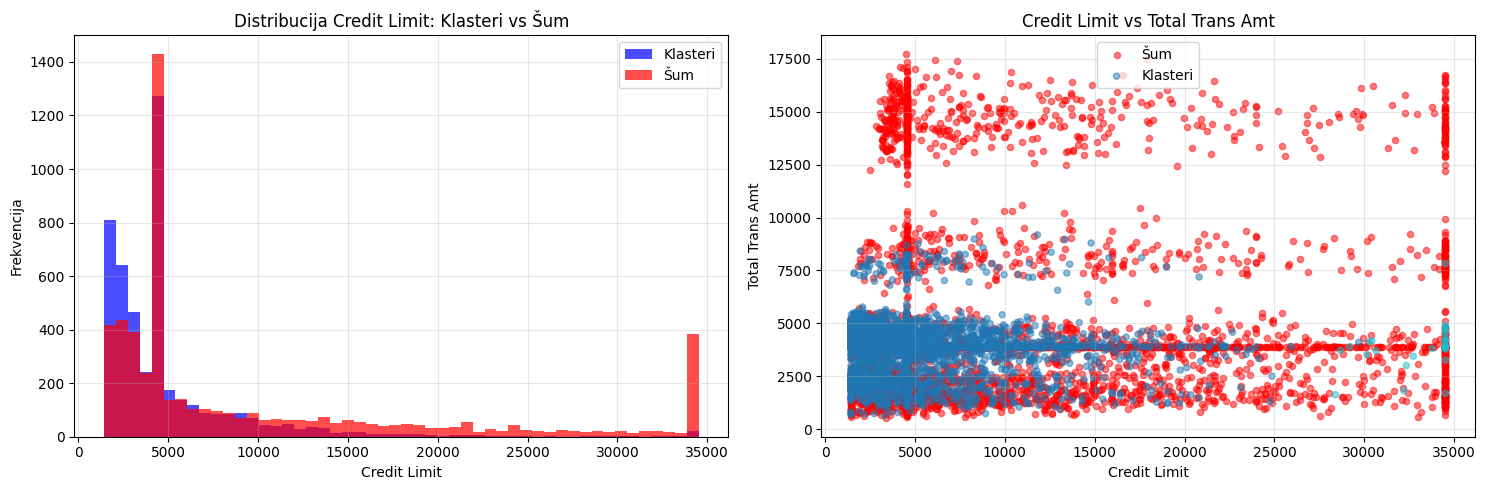


FINALNA EVALUACIJA I PREPORUKE

📊 KVALITET MODELA:
  ✓ Silhouette Score: 0.3320 - ODLIČAN ✅
  ✓ Davies-Bouldin Score: 0.9176 - ODLIČAN ✅
  ✓ Procenat šuma: 53.76% - UMJEREN ⚠️

💡 INTERPRETACIJA:
  • DBSCAN je pronašao 2 glavna klastera
  • 53.76% podataka je klasifikovano kao šum/outlieri
  • Ovo sugeriše da podaci imaju HETEROGENU strukturu - većina korisnika nema jasnu grupnu pripadnost

🎯 PREDNOSTI DBSCAN PRISTUPA NA OVIM PODACIMA:
  ✓ Automatski detektuje outliere (premium klijente, neaktivne korisnike)
  ✓ Ne pretpostavlja sferične klastere kao k-means
  ✓ Pronalazi male, guste grupe sa specifičnim karakteristikama

⚠️  OGRANIČENJA:
  • Visok procenat šuma može otežati operativnu primjenu
  • Mali klasteri mogu biti nestabilni
  • Zahtijeva pažljivo podešavanje parametara



In [ ]:
# ==========================================
# BLOK 12: Dodatna analiza šuma i malih klastera
# ==========================================

print("\n" + "="*80)
print("DODATNA ANALIZA - ŠUM I MALI KLASTERI")
print("="*80)

# Analiza šuma
noise_points = df_analyzed[df_analyzed['Cluster'] == -1]
if len(noise_points) > 0:
    print(f"\nKarakteristike ŠUM tačaka (n={len(noise_points)}):")
    if 'Credit_Limit_clean' in noise_points.columns:
        print(f"  Credit Limit - Mean: {noise_points['Credit_Limit_clean'].mean():.2f}, "
              f"Median: {noise_points['Credit_Limit_clean'].median():.2f}, "
              f"Std: {noise_points['Credit_Limit_clean'].std():.2f}")
    if 'Total_Trans_Amt_clean' in noise_points.columns:
        print(f"  Total Trans Amt - Mean: {noise_points['Total_Trans_Amt_clean'].mean():.2f}, "
              f"Median: {noise_points['Total_Trans_Amt_clean'].median():.2f}")

# Analiza malih klastera (< 5% ukupnih tačaka)
small_cluster_threshold = len(df_analyzed) * 0.05
for cluster_id in sorted(clusters_only['Cluster'].unique()):
    cluster_size = len(clusters_only[clusters_only['Cluster'] == cluster_id])
    if cluster_size < small_cluster_threshold:
        cluster_data = clusters_only[clusters_only['Cluster'] == cluster_id]
        print(f"\nKlaster {cluster_id} (MALI - {cluster_size} tačaka, {cluster_size/len(df_analyzed)*100:.2f}%):")

        if 'Credit_Limit_clean' in cluster_data.columns:
            cl_mean = cluster_data['Credit_Limit_clean'].mean()
            cl_global = clusters_only['Credit_Limit_clean'].mean()
            print(f"  Credit Limit: {cl_mean:.2f} (globalni prosek: {cl_global:.2f}, "
                  f"razlika: {(cl_mean/cl_global - 1)*100:+.1f}%)")

        if 'Total_Trans_Amt_clean' in cluster_data.columns:
            tt_mean = cluster_data['Total_Trans_Amt_clean'].mean()
            tt_global = clusters_only['Total_Trans_Amt_clean'].mean()
            print(f"  Total Trans Amt: {tt_mean:.2f} (globalni prosek: {tt_global:.2f})")

        # Obrazovanje
        if 'Education_Level_clean' in cluster_data.columns:
            edu_dist = cluster_data['Education_Level_clean'].value_counts()
            print(f"  Obrazovanje: {edu_dist.to_dict()}")

# Vizualizacija šuma vs klastera
if len(noise_points) > 0 and 'Credit_Limit_clean' in df_analyzed.columns:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Histogram Credit Limit
    axes[0].hist(clusters_only['Credit_Limit_clean'], bins=50, alpha=0.7,
                 label='Klasteri', color='blue')
    axes[0].hist(noise_points['Credit_Limit_clean'], bins=50, alpha=0.7,
                 label='Šum', color='red')
    axes[0].set_xlabel('Credit Limit')
    axes[0].set_ylabel('Frekvencija')
    axes[0].set_title('Distribucija Credit Limit: Klasteri vs Šum')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Scatter plot
    axes[1].scatter(noise_points['Credit_Limit_clean'],
                   noise_points['Total_Trans_Amt_clean'] if 'Total_Trans_Amt_clean' in noise_points.columns else noise_points.iloc[:, 0],
                   alpha=0.5, s=20, c='red', label='Šum')
    axes[1].scatter(clusters_only['Credit_Limit_clean'],
                   clusters_only['Total_Trans_Amt_clean'] if 'Total_Trans_Amt_clean' in clusters_only.columns else clusters_only.iloc[:, 0],
                   alpha=0.5, s=20, c=clusters_only['Cluster'], cmap='tab10', label='Klasteri')
    axes[1].set_xlabel('Credit Limit')
    axes[1].set_ylabel('Total Trans Amt')
    axes[1].set_title('Credit Limit vs Total Trans Amt')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

print("\n" + "="*80)
print("FINALNA EVALUACIJA I PREPORUKE")
print("="*80)

# Finalna procjena kvaliteta
if n_clusters_final > 1:
    noise_ratio = n_noise_final / len(final_labels)

    print(f"\n📊 KVALITET MODELA:")
    print(f"  ✓ Silhouette Score: {silhouette_final:.4f}", end="")
    if silhouette_final > 0.25:
        print(" - ODLIČAN ✅")
    elif silhouette_final > 0.15:
        print(" - DOBAR ✅")
    else:
        print(" - SLAB ⚠️")

    print(f"  ✓ Davies-Bouldin Score: {davies_bouldin_final:.4f}", end="")
    if davies_bouldin_final < 1.0:
        print(" - ODLIČAN ✅")
    elif davies_bouldin_final < 2.0:
        print(" - DOBAR ✅")
    else:
        print(" - SLAB ⚠️")

    print(f"  ✓ Procenat šuma: {noise_ratio*100:.2f}%", end="")
    if noise_ratio < 0.30:
        print(" - NIZAK ✅")
    elif noise_ratio < 0.55:
        print(" - UMJEREN ⚠️")
    else:
        print(" - VISOK ⚠️ (ali može biti legitimno za heterogene podatke)")

    print(f"\n💡 INTERPRETACIJA:")
    print(f"  • DBSCAN je pronašao {n_clusters_final} glavna klastera")
    print(f"  • {noise_ratio*100:.2f}% podataka je klasifikovano kao šum/outlieri")
    print(f"  • Ovo sugeriše da podaci imaju ", end="")
    if noise_ratio > 0.50:
        print("HETEROGENU strukturu - većina korisnika nema jasnu grupnu pripadnost")
    else:
        print("RELATIVNO JASNU klaster strukturu")

    print(f"\n🎯 PREDNOSTI DBSCAN PRISTUPA NA OVIM PODACIMA:")
    print(f"  ✓ Automatski detektuje outliere (premium klijente, neaktivne korisnike)")
    print(f"  ✓ Ne pretpostavlja sferične klastere kao k-means")
    print(f"  ✓ Pronalazi male, guste grupe sa specifičnim karakteristikama")

    print(f"\n⚠️  OGRANIČENJA:")
    print(f"  • Visok procenat šuma može otežati operativnu primjenu")
    print(f"  • Mali klasteri mogu biti nestabilni")
    print(f"  • Zahtijeva pažljivo podešavanje parametara")

print("\n" + "="*80)